In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
!unzip quora-question-pairs.zip

Archive:  quora-question-pairs.zip
  inflating: sample_submission.csv.zip  
  inflating: test.csv                
  inflating: test.csv.zip            
  inflating: train.csv.zip           


In [4]:
!unzip train.csv.zip
df = pd.read_csv('train.csv')


Archive:  train.csv.zip
  inflating: train.csv               


In [7]:
df.sample(10)

,id,qid1,qid2,question1,question2,is_duplicate
125140,125140,201939,201940,How do I deal with passive aggressive mother?,How do I deal with a passive aggressive mother?,1
84592,84592,142998,83693,What should I do with my drawings?,Why is my employer suing me for walking off th...,0
188222,188222,286682,286683,What does Spanish sound like to foreigners?,Why does the Spanish word for 'brother' not so...,0
183542,183542,6781,62590,What are some of your favorite books?,What are your top 5 favorite books?,1
306526,306526,430073,430074,Which letter in which language is worth the mo...,What language is most worth studying?,0
223240,223240,7948,29642,Why do people still think the the world is flat?,Why do some people think the Earth is flat?,1
261067,261067,5307,54721,Does Lipton green tea Assist in weight loss?,What is the correct time to take green tea for...,1
381669,381669,377540,301984,What is the blood group of a mosquito?,Do animals have blood groups?,0
2574,2574,5114,5115,Why do you write fiction?,How exactly DO you write a story?,0
255716,255716,370667,370668,How often do you clean your gas grill?,How do you clean a gas grill?,0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 404290 entries, 0 to 404289
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            404290 non-null  int64 
 1   qid1          404290 non-null  int64 
 2   qid2          404290 non-null  int64 
 3   question1     404289 non-null  object
 4   question2     404288 non-null  object
 5   is_duplicate  404290 non-null  int64 
dtypes: int64(4), object(2)
memory usage: 18.5+ MB


In [10]:
df.isnull().sum()

id              0
qid1            0
qid2            0
question1       1
question2       2
is_duplicate    0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

is_duplicate
0    255027
1    149263
Name: count, dtype: int64
is_duplicate
0    63.080215
1    36.919785
Name: count, dtype: float64


<Axes: xlabel='is_duplicate'>

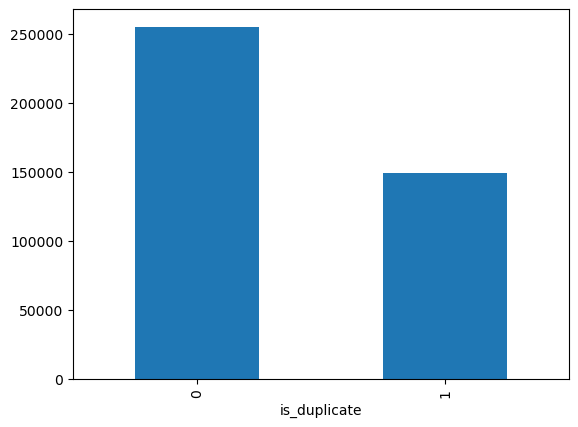

In [12]:
#distribution of duplicate and non-duplicate questions
print(df['is_duplicate'].value_counts())
print((df['is_duplicate'].value_counts()/df['is_duplicate'].count())*100)
df['is_duplicate'].value_counts().plot(kind='bar')

In [13]:
# Repeated questions

qid = pd.Series(df['qid1'].tolist() + df['qid2'].tolist())
print('Number of unique questions',np.unique(qid).shape[0])
x = qid.value_counts()>1
print('Number of questions getting repeated',x[x].shape[0])

Number of unique questions 537933
Number of questions getting repeated 111780


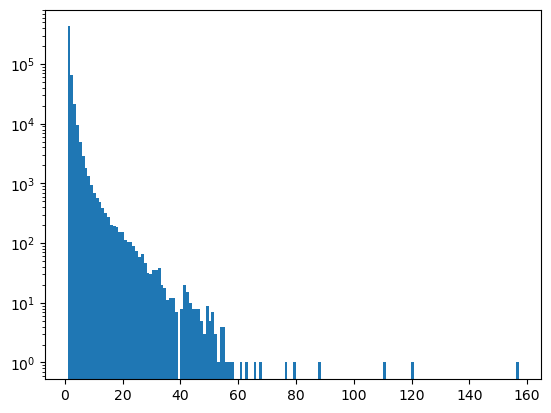

In [14]:
# Repeated questions histogram

plt.hist(qid.value_counts().values,bins=160)
plt.yscale('log')
plt.show()

In [15]:
new_df = df.sample(50000)

In [21]:
new_df.isnull().sum()

id              0
qid1            0
qid2            0
question1       1
question2       0
is_duplicate    0
dtype: int64

In [22]:
new_df.dropna(inplace=True)

In [23]:
ques_df = new_df[['question1','question2']]
ques_df.head()

,question1,question2
27112,How do I get rid of a cold fast?,What's the quickest way to get rid of a cold?
370970,What are the Top 50 most used IPC sections?,Do we need the IPC section 375?
285226,Do I really need serializers in Django Rest Fr...,How do I do basic serialization in Django REST...
139362,In what ways are you privileged and in what wa...,What are some ways you are privileged?
295875,Which is the best place for vacation?,Where is the best place to vacation?


In [24]:
from sklearn.feature_extraction.text import CountVectorizer

questions = list(ques_df['question1']) + list(ques_df['question2'])

cv = CountVectorizer(max_features=3000)
q1_arr, q2_arr = np.vsplit(cv.fit_transform(questions).toarray(),2)


In [25]:
temp_df1 = pd.DataFrame(q1_arr, index= ques_df.index)
temp_df2 = pd.DataFrame(q2_arr, index= ques_df.index)
temp_df = pd.concat([temp_df1, temp_df2], axis=1)
temp_df.shape

(49999, 6000)

In [27]:
temp_df['is_duplicate'] = new_df['is_duplicate']

In [28]:
temp_df

,0,1,2,3,4,5,6,7,8,9,...,2991,2992,2993,2994,2995,2996,2997,2998,2999,is_duplicate
27112,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
370970,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
285226,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
139362,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
295875,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
230810,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
173568,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
129972,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
26080,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,1


In [29]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(temp_df.iloc[:,0:-1].values,temp_df.iloc[:,-1].values,test_size=0.2,random_state=1)

In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
rf = RandomForestClassifier()
rf.fit(X_train,y_train)
y_pred = rf.predict(X_test)
accuracy_score(y_test,y_pred)

0.7559

In [31]:
from xgboost import XGBClassifier
xgb = XGBClassifier()
xgb.fit(X_train,y_train)
y_pred = xgb.predict(X_test)
accuracy_score(y_test,y_pred)

0.7348

In [32]:
# Feature Engineering

new_df['q1_len'] = new_df['question1'].str.len() 
new_df['q2_len'] = new_df['question2'].str.len()

In [33]:
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len
27112,27112,50389,50390,How do I get rid of a cold fast?,What's the quickest way to get rid of a cold?,1,32,45
370970,370970,421332,905,What are the Top 50 most used IPC sections?,Do we need the IPC section 375?,0,43,31
285226,285226,405612,405613,Do I really need serializers in Django Rest Fr...,How do I do basic serialization in Django REST...,0,58,57
139362,139362,64658,221705,In what ways are you privileged and in what wa...,What are some ways you are privileged?,0,61,38
295875,295875,417986,417987,Which is the best place for vacation?,Where is the best place to vacation?,1,37,36


In [34]:
new_df['q1_num_words'] = new_df['question1'].apply(lambda row: len(row.split(" ")))
new_df['q2_num_words'] = new_df['question2'].apply(lambda row: len(row.split(" ")))
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words
27112,27112,50389,50390,How do I get rid of a cold fast?,What's the quickest way to get rid of a cold?,1,32,45,9,10
370970,370970,421332,905,What are the Top 50 most used IPC sections?,Do we need the IPC section 375?,0,43,31,9,7
285226,285226,405612,405613,Do I really need serializers in Django Rest Fr...,How do I do basic serialization in Django REST...,0,58,57,10,10
139362,139362,64658,221705,In what ways are you privileged and in what wa...,What are some ways you are privileged?,0,61,38,13,7
295875,295875,417986,417987,Which is the best place for vacation?,Where is the best place to vacation?,1,37,36,7,7


In [35]:
def common_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))    
    return len(w1 & w2)

In [36]:
new_df['word_common'] = new_df.apply(common_words, axis=1)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common
27112,27112,50389,50390,How do I get rid of a cold fast?,What's the quickest way to get rid of a cold?,1,32,45,9,10,4
370970,370970,421332,905,What are the Top 50 most used IPC sections?,Do we need the IPC section 375?,0,43,31,9,7,2
285226,285226,405612,405613,Do I really need serializers in Django Rest Fr...,How do I do basic serialization in Django REST...,0,58,57,10,10,5
139362,139362,64658,221705,In what ways are you privileged and in what wa...,What are some ways you are privileged?,0,61,38,13,7,4
295875,295875,417986,417987,Which is the best place for vacation?,Where is the best place to vacation?,1,37,36,7,7,5


In [37]:
def total_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))    
    return (len(w1) + len(w2))

In [38]:
new_df['word_total'] = new_df.apply(total_words, axis=1)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total
27112,27112,50389,50390,How do I get rid of a cold fast?,What's the quickest way to get rid of a cold?,1,32,45,9,10,4,19
370970,370970,421332,905,What are the Top 50 most used IPC sections?,Do we need the IPC section 375?,0,43,31,9,7,2,16
285226,285226,405612,405613,Do I really need serializers in Django Rest Fr...,How do I do basic serialization in Django REST...,0,58,57,10,10,5,19
139362,139362,64658,221705,In what ways are you privileged and in what wa...,What are some ways you are privileged?,0,61,38,13,7,4,14
295875,295875,417986,417987,Which is the best place for vacation?,Where is the best place to vacation?,1,37,36,7,7,5,14


In [39]:
new_df['word_share'] = round(new_df['word_common']/new_df['word_total'],2)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share
27112,27112,50389,50390,How do I get rid of a cold fast?,What's the quickest way to get rid of a cold?,1,32,45,9,10,4,19,0.21
370970,370970,421332,905,What are the Top 50 most used IPC sections?,Do we need the IPC section 375?,0,43,31,9,7,2,16,0.12
285226,285226,405612,405613,Do I really need serializers in Django Rest Fr...,How do I do basic serialization in Django REST...,0,58,57,10,10,5,19,0.26
139362,139362,64658,221705,In what ways are you privileged and in what wa...,What are some ways you are privileged?,0,61,38,13,7,4,14,0.29
295875,295875,417986,417987,Which is the best place for vacation?,Where is the best place to vacation?,1,37,36,7,7,5,14,0.36


In [40]:
ques_df = new_df[['question1','question2']]
ques_df.head()

,question1,question2
27112,How do I get rid of a cold fast?,What's the quickest way to get rid of a cold?
370970,What are the Top 50 most used IPC sections?,Do we need the IPC section 375?
285226,Do I really need serializers in Django Rest Fr...,How do I do basic serialization in Django REST...
139362,In what ways are you privileged and in what wa...,What are some ways you are privileged?
295875,Which is the best place for vacation?,Where is the best place to vacation?


In [41]:
final_df = new_df.drop(columns=['id','qid1','qid2','question1','question2'])
print(final_df.shape)
final_df.head()

(49999, 8)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share
27112,1,32,45,9,10,4,19,0.21
370970,0,43,31,9,7,2,16,0.12
285226,0,58,57,10,10,5,19,0.26
139362,0,61,38,13,7,4,14,0.29
295875,1,37,36,7,7,5,14,0.36


In [42]:
from sklearn.feature_extraction.text import CountVectorizer
# merge texts
questions = list(ques_df['question1']) + list(ques_df['question2'])

cv = CountVectorizer(max_features=3000)
q1_arr, q2_arr = np.vsplit(cv.fit_transform(questions).toarray(),2)


In [48]:
temp_df1 = pd.DataFrame(q1_arr, index= ques_df.index)
temp_df2 = pd.DataFrame(q2_arr, index= ques_df.index)
temp_df = pd.concat([temp_df1, temp_df2], axis=1)
temp_df.shape
temp_df.head()

,0,1,2,3,4,5,6,7,8,9,...,2990,2991,2992,2993,2994,2995,2996,2997,2998,2999
27112,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
370970,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
285226,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
139362,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
295875,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [44]:
final_df = pd.concat([final_df, temp_df], axis=1)
print(final_df.shape)
final_df.head()

(49999, 6008)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,0,1,...,2990,2991,2992,2993,2994,2995,2996,2997,2998,2999
27112,1,32,45,9,10,4,19,0.21,0,0,...,0,0,0,0,0,0,0,0,0,0
370970,0,43,31,9,7,2,16,0.12,0,0,...,0,0,0,0,0,0,0,0,0,0
285226,0,58,57,10,10,5,19,0.26,0,0,...,0,0,0,0,0,0,0,0,0,0
139362,0,61,38,13,7,4,14,0.29,0,0,...,0,0,1,0,0,0,0,0,0,0
295875,1,37,36,7,7,5,14,0.36,0,0,...,0,0,0,0,0,0,0,0,0,0


In [45]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(final_df.iloc[:,1:].values,final_df.iloc[:,0].values,test_size=0.2,random_state=1)

In [46]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
rf = RandomForestClassifier()
rf.fit(X_train,y_train)
y_pred = rf.predict(X_test)
accuracy_score(y_test,y_pred)

0.78

In [47]:
from xgboost import XGBClassifier
xgb = XGBClassifier()
xgb.fit(X_train,y_train)
y_pred = xgb.predict(X_test)
accuracy_score(y_test,y_pred)

0.7717